# Phase unwrapping

Interferometers, holograms, phase shifting algorithms and `np.angle()` only
give the phase modulo $2\pi$: the *wrapped* phase
$\psi = \mathcal{W}(\varphi) \in [-\pi, \pi)$. Unwrapping restores
$\varphi = \psi + 2\pi n$ with integers $n$, assuming that the true phase changes
by less than $\pi$ between neighbouring pixels (the *Itoh condition*). Then the
wrapped differences $\mathcal{W}(\Delta\psi)$ are the true differences
$\Delta\varphi$, and integrating them gives $\varphi$ up to a constant.

In 2D the integral may depend on the path: wherever the wrapped differences
around a closed loop of $2\times2$ pixels do not sum to zero there is a
*residue* (a phase vortex, a noise point or an undersampled region).
`pyoptics.unwrap` offers two strategies:

| Function | Idea | Result |
|---|---|---|
| `unwrap_ls(psi)` | least squares: the $\varphi$ whose gradient is closest to $\mathcal{W}(\nabla\psi)$; a Poisson equation solved by one DCT (Ghiglia and Romero 1994) | smooth, robust, not congruent |
| `unwrap_ls(psi, weights=w, mask=m)` | weighted least squares by conjugate gradients, preconditioned with the DCT solver | weights downweight bad pixels |
| `unwrap_ls(..., congruent=True)` | the congruent phase nearest to the least squares solution | congruent |
| `unwrap_quality_guided(psi, quality=q)` | join pixel pairs in the order of their reliability (Herráez et al. 2002) | congruent, errors confined to bad regions |
| `residues(psi)`, `reliability(psi)`, `wrap(phi)`, `unwrap_1d(psi)` | helpers | |

*Congruent* means $\mathcal{W}(\varphi) = \psi$: the result reproduces the data
exactly. All functions take arrays indexed `[y, x]`, treat NaN as masked and
return NaN outside the mask. The piston is arbitrary; it is chosen such that the
result agrees with the data modulo $2\pi$ and has its mean in $(-\pi, \pi]$.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics.bases import FringeZernikes
from pyoptics.processing import CameraNoiser
from pyoptics.unwrap import (wrap, unwrap_1d, unwrap_ls, unwrap_quality_guided,
                             residues, reliability)
from pyoptics.utils import grid2d

plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower", "font.size": 11})


def show(ax, img, title, cmap="viridis", **kwargs):
    im = ax.imshow(img, extent=extent, cmap=cmap, **kwargs)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return im


def remove_piston(u, phi):
    # compare unwrapped results with the truth up to a constant
    d = u - phi
    return d - np.nanmedian(d)


N = 256
x, y, X, Y = grid2d(-1, 1, -1, 1, N)
extent = (x[0], x[-1], y[0], y[-1])

## 1. One dimension: the Itoh condition

In 1D unwrapping is unique: add $2\pi$ wherever the wrapped phase jumps by more
than $\pi$ (`numpy.unwrap`, available as `unwrap_1d`). It fails as soon as the
true phase changes by more than $\pi$ per sample. Here a quadratic phase (a
defocus) gets steeper towards the edge; beyond the sample at which the local
phase step reaches $\pi$, the unwrapped phase falls off the true one.

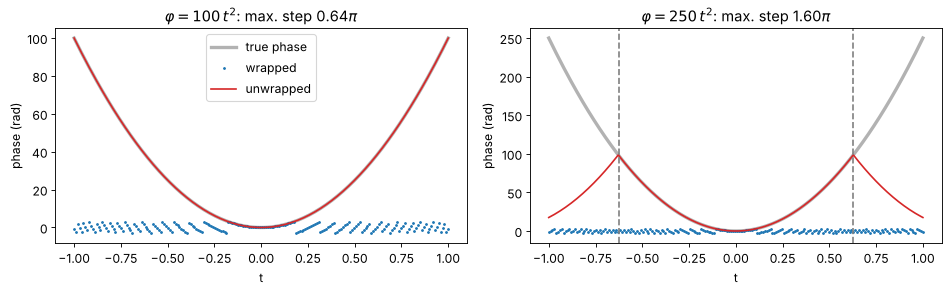

In [2]:
t = np.linspace(-1, 1, 200)
dt = t[1] - t[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, a in zip(axes, [100, 250]):
    phi = a*t**2
    psi = wrap(phi)
    u = unwrap_1d(psi)
    u += phi[100] - u[100]
    ax.plot(t, phi, "k", lw=3, alpha=0.3, label="true phase")
    ax.plot(t, psi, ".", ms=3, label="wrapped")
    ax.plot(t, u, "C3", label="unwrapped")
    t_lim = np.pi/(2*a*dt)  # |dφ/dt| dt = π
    if t_lim < 1:
        for s in (-1, 1):
            ax.axvline(s*t_lim, color="gray", ls="--")
    ax.set_title(r"$\varphi = %d\,t^2$: max. step %.2f$\pi$" % (a, 2*a*dt/np.pi))
    ax.set_xlabel("t"); ax.set_ylabel("phase (rad)")
axes[0].legend()
plt.tight_layout()

The dashed lines mark where the phase step per sample reaches $\pi$. Outside of
them the samples alias: the unwrapped phase follows a wrong branch. The same
limit holds in 2D, where it also produces residues.

## 2. A wavefront in a circular pupil

A wavefront with defocus, astigmatism, coma and spherical aberration of a few
waves each, wrapped many times. Outside the pupil the camera sees noise. Both
algorithms recover the wavefront to machine precision once they are told the
pupil (`mask`); without the mask, the noise outside spoils least squares.

LS, no mask      max |error| = 6.96e+00 rad
LS, mask         max |error| = 1.15e-09 rad
quality guided   max |error| = 1.42e-14 rad


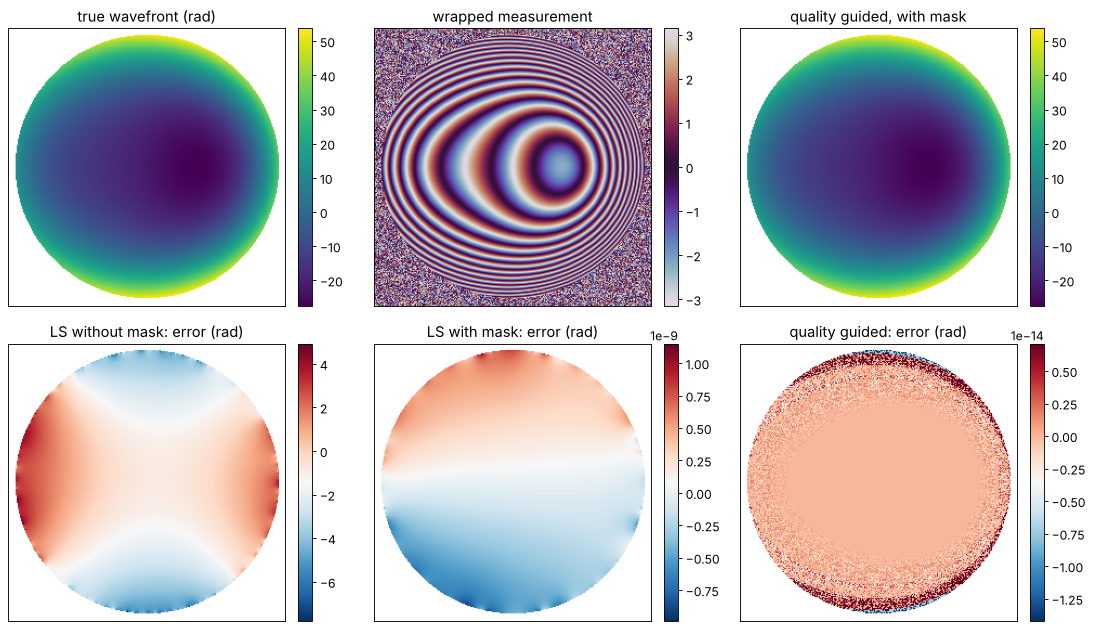

In [3]:
Z = FringeZernikes(x, y, R_norm=0.95)
pupil = Z.mask.astype(bool)
phi = Z([4, 5, 7, 9], [30.0, -15.0, 10.0, 8.0])     # radians
rng = np.random.default_rng(1)
psi = np.where(pupil, wrap(phi), rng.uniform(-np.pi, np.pi, phi.shape))

u_ls_nomask = unwrap_ls(psi)
u_ls = unwrap_ls(psi, mask=pupil)
u_qg = unwrap_quality_guided(psi, mask=pupil)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
show(axes[0, 0], np.where(pupil, phi, np.nan), "true wavefront (rad)")
show(axes[0, 1], psi, "wrapped measurement", cmap="twilight")
show(axes[0, 2], u_qg, "quality guided, with mask")
show(axes[1, 0], np.where(pupil, remove_piston(u_ls_nomask, phi), np.nan),
     "LS without mask: error (rad)", cmap="RdBu_r")
show(axes[1, 1], remove_piston(u_ls, phi), "LS with mask: error (rad)", cmap="RdBu_r")
show(axes[1, 2], remove_piston(u_qg, phi), "quality guided: error (rad)", cmap="RdBu_r")
plt.tight_layout()

for name, u in [("LS, no mask", np.where(pupil, u_ls_nomask, np.nan)),
                ("LS, mask", u_ls), ("quality guided", u_qg)]:
    print("%-16s max |error| = %.2e rad" % (name, np.nanmax(np.abs(remove_piston(u, phi)))))

With the mask, the weighted least squares solver needs only a few conjugate
gradient iterations, since the unweighted DCT solver is an excellent
preconditioner:

In [4]:
_, info = unwrap_ls(psi, mask=pupil, return_info=True)
print(info)

{'iterations': 14, 'residual': np.float64(3.900583437211906e-11)}


## 3. Residues: where the path matters

A field with an optical vortex pair, $(x - x_1 + i(y - y_1))\,(x - x_2 - i(y - y_2))$,
has a phase singularity of charge $+1$ at $(x_1, y_1)$ and $-1$ at
$(x_2, y_2)$, on top of a smooth wavefront. `residues()` finds them: the wrapped
differences around the $2\times2$ loop containing a core add up to $\pm 2\pi$.

No continuous phase can represent this field: any congruent unwrapped phase
needs a $2\pi$ jump (a *branch cut*) that connects the two vortices.

- Least squares spreads the inconsistency over the whole image: the result is
  smooth everywhere, but it is not congruent ($\mathcal{W}(\varphi_{LS}) \neq \psi$)
  and is distorted around the vortices.
- `congruent=True` snaps it to the data; the cut appears where the least
  squares solution is $\pi$ away from it.
- The quality guided algorithm puts the cut through the least reliable
  pixels, which are near the vortices.

residues: 1 positive, 1 negative, total charge 0


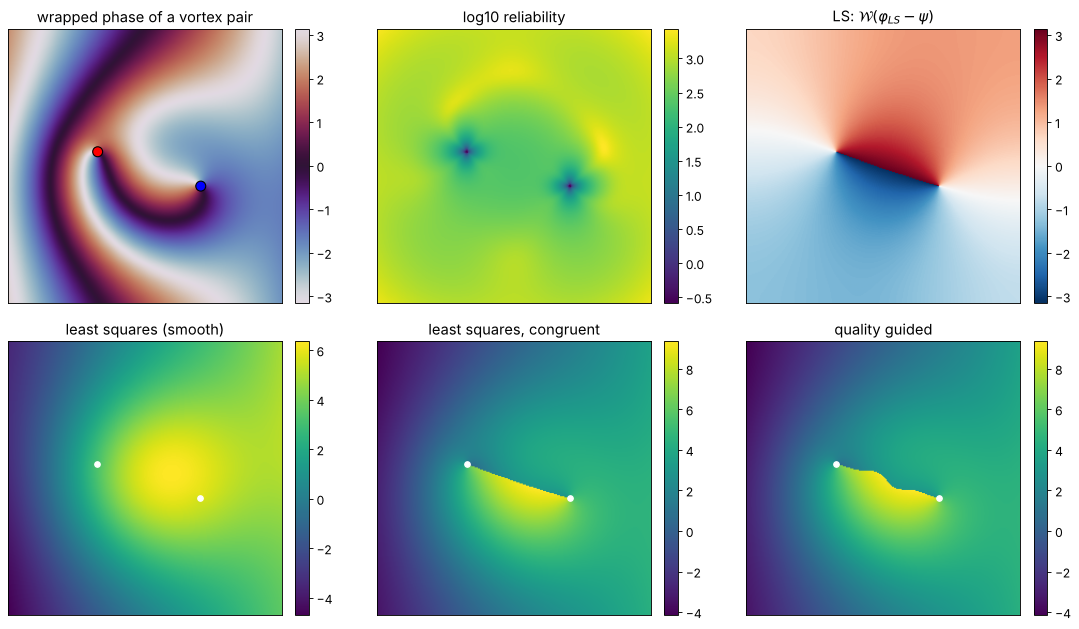

In [5]:
x1, y1, x2, y2 = -0.35, 0.1, 0.4, -0.15
smooth = 6*np.exp(-(X**2 + Y**2)/0.5) + 4*X
E = (X - x1 + 1j*(Y - y1))*(X - x2 - 1j*(Y - y2))*np.exp(1j*smooth)
psi_v = np.angle(E)
res = residues(psi_v)
print("residues: %d positive, %d negative, total charge %d"
      % (np.sum(res > 0), np.sum(res < 0), res.sum()))

u_ls = unwrap_ls(psi_v)
u_ls_c = unwrap_ls(psi_v, congruent=True)
u_qg = unwrap_quality_guided(psi_v)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
show(axes[0, 0], psi_v, "wrapped phase of a vortex pair", cmap="twilight")
iy, ix = np.nonzero(res)
xc, yc = x[:-1] + (x[1] - x[0])/2, y[:-1] + (y[1] - y[0])/2
axes[0, 0].scatter(xc[ix], yc[iy], c=res[iy, ix], cmap="bwr", vmin=-1, vmax=1,
                   s=80, edgecolors="k")
show(axes[0, 1], np.log10(reliability(psi_v)[1:-1, 1:-1]), "log10 reliability")
show(axes[0, 2], wrap(u_ls - psi_v), r"LS: $\mathcal{W}(\varphi_{LS} - \psi)$",
     cmap="RdBu_r", vmin=-np.pi, vmax=np.pi)
show(axes[1, 0], u_ls, "least squares (smooth)")
show(axes[1, 1], u_ls_c, "least squares, congruent")
show(axes[1, 2], u_qg, "quality guided")
for ax in axes[1]:
    ax.plot([x1, x2], [y1, y2], "w.", ms=10)
plt.tight_layout()

The top right panel shows how far the smooth least squares solution is from
the data: up to $\pi$ along the line between the vortices, and still visibly
off elsewhere. The two congruent results both contain a cut that starts and
ends on the vortices (white dots), only its route differs.

## 4. Noise and low modulation

Real wrapped phases are noisy. We take the field $\sqrt{N_\mathrm{ph}}\,a(x,y)\,e^{i\varphi}$,
whose amplitude $a$ drops to almost zero in two dark spots (e.g. dust
particles), add complex Gaussian camera noise with `CameraNoiser`, and
unwrap $\psi = \arg E$. The phase noise is about $1/(\sqrt{N_\mathrm{ph}}\,a)$,
so the dark spots are pure noise and full of residues.

- Unweighted least squares lets the noise in the spots bend the result
  around them.
- Weighting by the measured intensity $|E|^2$ suppresses the spots.
- Quality guided unwrapping with the reliability map (or the amplitude as
  quality) unwraps the good pixels first.

rms error where a > 0.3 (expected phase noise 0.075 rad):
  LS, unweighted                 0.106 rad, pixels off by 2π: 0
  LS, weights |E|²               0.075 rad, pixels off by 2π: 0
  quality guided (reliability)   0.075 rad, pixels off by 2π: 0
  quality guided (|E|)           0.075 rad, pixels off by 2π: 0


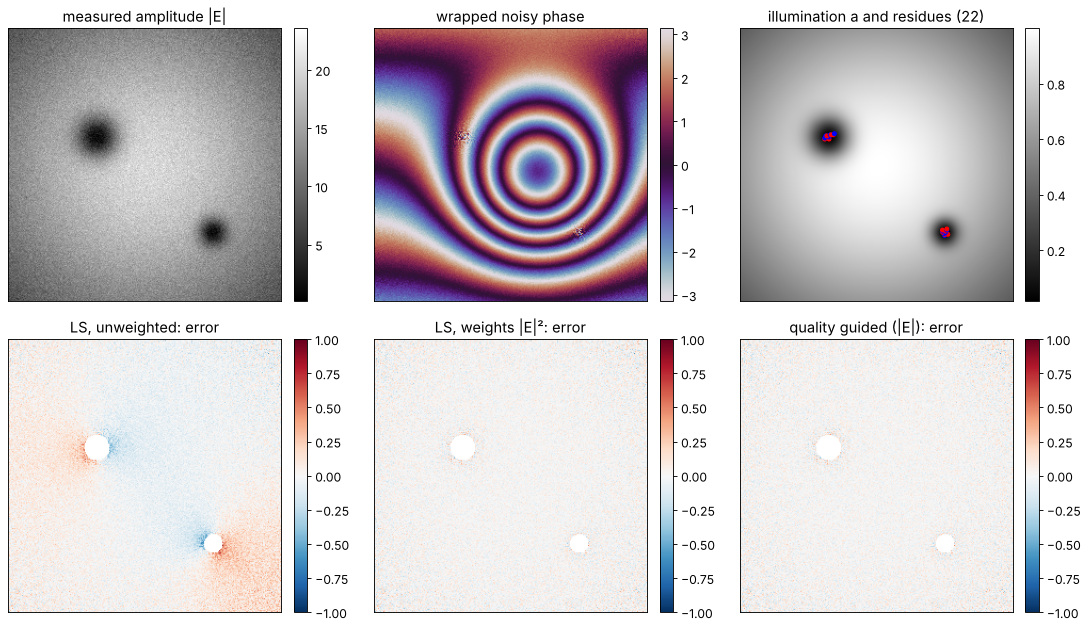

In [6]:
phi = 25*np.exp(-((X - 0.2)**2 + (Y + 0.1)**2)/0.3) + 8*Y
a = np.exp(-(X**2 + Y**2)/2)  # Gaussian illumination with two dust spots
a *= 1 - 0.98*np.exp(-((X + 0.35)**2 + (Y - 0.2)**2)/0.15**2)
a *= 1 - 0.98*np.exp(-((X - 0.5)**2 + (Y + 0.5)**2)/0.1**2)
noiser = CameraNoiser("gaussian", sigma=1.0, rng=3)
E_n = noiser(np.sqrt(400.0)*a*np.exp(1j*phi))
psi_n = np.angle(E_n)
A = np.abs(E_n)

results = {
    "LS, unweighted": unwrap_ls(psi_n),
    "LS, weights |E|²": unwrap_ls(psi_n, weights=A**2),
    "quality guided (reliability)": unwrap_quality_guided(psi_n),
    "quality guided (|E|)": unwrap_quality_guided(psi_n, quality=A),
}

good = a > 0.3  # where the measurement is meaningful
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
show(axes[0, 0], A, "measured amplitude |E|", cmap="gray")
show(axes[0, 1], psi_n, "wrapped noisy phase", cmap="twilight")
r = residues(psi_n)
show(axes[0, 2], a, "illumination a and residues (%d)" % np.count_nonzero(r), cmap="gray")
iy, ix = np.nonzero(r)
xc, yc = x[:-1] + (x[1] - x[0])/2, y[:-1] + (y[1] - y[0])/2
axes[0, 2].scatter(xc[ix], yc[iy], c=r[iy, ix], cmap="bwr", vmin=-1, vmax=1, s=12)
for ax, (name, u) in zip(axes[1], list(results.items())[:2] + list(results.items())[3:]):
    d = remove_piston(u, phi)
    show(ax, np.where(good, d, np.nan), name + ": error", cmap="RdBu_r", vmin=-1, vmax=1)
plt.tight_layout()

print("rms error where a > 0.3 (expected phase noise %.3f rad):"
      % np.sqrt(np.mean(1/(400*a[good]**2))))
for name, u in results.items():
    d = remove_piston(u, phi)[good]
    d -= np.median(d)
    print("  %-30s %.3f rad, pixels off by 2π: %d"
          % (name, np.sqrt(np.mean(d**2)), np.sum(np.abs(d) > np.pi)))

The unweighted least squares solution is smooth but biased around the spots,
with errors well above the noise. Weights remove the bias. The quality guided
results are congruent, so their error equals the measurement noise on the
good pixels.

### Error versus signal

The rms error over the well exposed region as a function of the photon
number. At low signal, residues appear everywhere and every method breaks
down. From about 100 photons per pixel on, the quality guided and the
weighted least squares results reach the noise limit $1/(\sqrt{N_\mathrm{ph}}\,a)$.

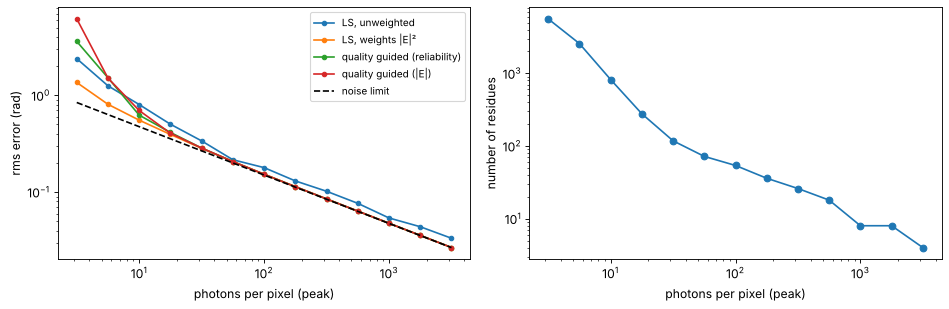

In [7]:
photons = np.logspace(0.5, 3.5, 13)
names = list(results)
err = {n: [] for n in names}
n_res = []
for Nph in photons:
    E_n = CameraNoiser("gaussian", sigma=1.0, rng=5)(np.sqrt(Nph)*a*np.exp(1j*phi))
    psi_n, A = np.angle(E_n), np.abs(E_n)
    n_res.append(np.count_nonzero(residues(psi_n)))
    us = [unwrap_ls(psi_n), unwrap_ls(psi_n, weights=A**2),
          unwrap_quality_guided(psi_n), unwrap_quality_guided(psi_n, quality=A)]
    for n, u in zip(names, us):
        d = remove_piston(u, phi)[good]
        err[n].append(np.sqrt(np.mean((d - np.median(d))**2)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for n in names:
    axes[0].loglog(photons, err[n], "o-", ms=4, label=n)
axes[0].loglog(photons, [np.sqrt(np.mean(1/(p*a[good]**2))) for p in photons],
               "k--", label="noise limit")
axes[0].set_xlabel("photons per pixel (peak)"); axes[0].set_ylabel("rms error (rad)")
axes[0].legend(fontsize=9)
axes[1].loglog(photons, n_res, "o-")
axes[1].set_xlabel("photons per pixel (peak)"); axes[1].set_ylabel("number of residues")
plt.tight_layout()

## 5. Holes and disconnected regions

Pupils often have holes: a central obscuration, spider vanes, dust. Pass them as
`mask`, or as NaN in the wrapped phase. Regions that are not connected by valid
pixels cannot be related to each other, so the quality guided algorithm gives
each of them its own piston (a multiple of $2\pi$). Least squares connects them
only through its smoothness, i.e. by arbitrary, not even $2\pi$-quantized
offsets.

upper half: offset -2.000000·2π, spread 2.1e-14 rad
lower half: offset 1.000000·2π, spread 1.2e-14 rad
least squares: max. error spread over all regions 1.67 rad


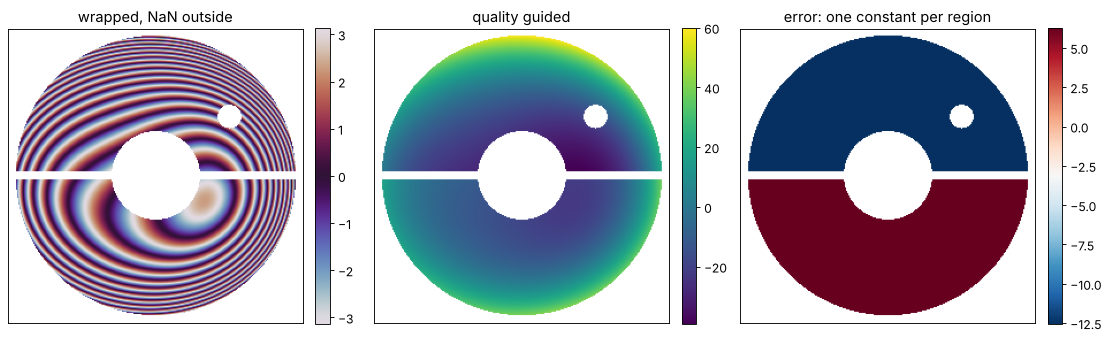

In [8]:
R = np.hypot(X, Y)
phi = Z([4, 5, 7, 9], [30.0, -15.0, 10.0, 8.0]) + 20*Y
mask = (R < 0.95) & (R > 0.3) & (np.abs(Y) > 0.03)  # obscuration and a spider vane
mask &= np.hypot(X - 0.5, Y - 0.4) > 0.08          # dust
psi = np.where(mask, wrap(phi), np.nan)
u = unwrap_quality_guided(psi)
u_ls = unwrap_ls(psi)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
show(axes[0], psi, "wrapped, NaN outside", cmap="twilight")
show(axes[1], u, "quality guided")
show(axes[2], u - phi, "error: one constant per region", cmap="RdBu_r")
plt.tight_layout()
for region, name in [(Y > 0, "upper half"), (Y < 0, "lower half")]:
    d = (u - phi)[mask & region]
    print("%s: offset %.6f·2π, spread %.1e rad" % (name, np.mean(d)/(2*np.pi), np.ptp(d)))
print("least squares: max. error spread over all regions %.2f rad" % np.nanmax(np.abs(remove_piston(u_ls, phi))))

Within each half the error is constant to machine precision, but the two
halves are off by different multiples of $2\pi$. This ambiguity only additional information (another
measurement, or a model of the wavefront) can resolve.

## 6. Speed

The DCT solver is an $O(N^2 \log N)$ operation. The quality guided algorithm
is dominated by sorting the $2N^2$ edges plus a Python loop over them
(union-find), which still unwraps a megapixel image in a few seconds.

In [9]:
for n in [128, 256, 512, 1024]:
    xs, ys, Xs, Ys = grid2d(-1, 1, -1, 1, n)
    psi_s = wrap(40*np.exp(-(Xs**2 + Ys**2)/0.3) + 10*Xs)
    times = []
    for f, kw in [(unwrap_ls, {}), (unwrap_ls, {"weights": np.ones((n, n))}),
                  (unwrap_quality_guided, {})]:
        t0 = time.perf_counter(); f(psi_s, **kw); times.append(time.perf_counter() - t0)
    print("N = %4d: LS (DCT) %.3f s, weighted LS (PCG) %.3f s, quality guided %.2f s"
          % (n, *times))

N =  128: LS (DCT) 0.003 s, weighted LS (PCG) 0.003 s, quality guided 0.05 s


N =  256: LS (DCT) 0.009 s, weighted LS (PCG) 0.018 s, quality guided 0.23 s


N =  512: LS (DCT) 0.061 s, weighted LS (PCG) 0.087 s, quality guided 1.05 s


N = 1024: LS (DCT) 0.521 s, weighted LS (PCG) 0.518 s, quality guided 4.43 s


## Summary

- Use `unwrap_quality_guided()` when the result has to reproduce the data
  (metrology, phase maps that are compared pixel by pixel). Give it a quality
  map such as the modulation of a phase shifting measurement if you have one.
- Use `unwrap_ls()` for a smooth, robust estimate, with `weights` (modulation,
  amplitude) and `mask` whenever parts of the image are bad, and
  `congruent=True` to snap it back to the data.
- Check `residues()` first: without residues all methods agree exactly (up to
  the piston); many residues mean undersampling or too much noise.

**References:** D. C. Ghiglia and L. A. Romero, JOSA A 11, 107 (1994);
M. A. Herráez et al., Appl. Opt. 41, 7437 (2002); D. C. Ghiglia and
M. D. Pritt, *Two-Dimensional Phase Unwrapping* (Wiley, 1998).